In the following we want to implement Rogers' algorithm. Their results are based on the following :
$$
Y_0^* = \inf_{M \in H^1_0} \mathbb{E}[ \sup_{t \in [0,T]} ( Z_t - M_t )].
$$
Therefore what we try to do is to pick a suitable martingale and evaluate the expectation.

We are going to use Haugh-Kogan approach.

The martingale we are going to use is $ \pi_{t+1}  =  \pi_t + \frac{\widetilde V_{t+1}}{B_{t+1}} - \frac{\widetilde V_t}{B_t} - \mathbb{E}_{t}\left[ \frac{\widetilde V_{t+1}}{B_{t+1}} - \frac{\widetilde V_t}{B_t} \right] = \pi_t  + \frac{\widetilde V_{t+1}}{B_{t+1}} - \mathbb{E}_{t}\left[ \frac{\widetilde V_{t+1}}{B_{t+1}} \right]$, where $\pi_0 = \tilde{V}_0$. therefore our quantity of interest is :


Given that in order to compute the upper bound using Rogers-Kaugh-Hogan algorithm it is necessary to have an approximation of the value of the american option, we need to first compute the primal problem using Longstaff-Schwartz.

In [1]:
from code_utils import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# LS  + Rogers/Haugh/Kogan

# Parameters
K = 100 # Strike price
sigma = 0.3 # Volatility 
r = 0.05  # Risk-free rate
q = 0 # Dividend yield
mu = r - q  # Drift 
T = 0.2  # Maturity 
dt = 0.004  # Time step 
N = int(T / dt) # Number of steps 
npaths_train = 10**5 # Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**6 # Number of paths for estimating the price of the option 
max_deg = 4 # Degree of the polynomial basis for regression
seed = 42 # Random seed for reproducibility

real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
                        30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
                        20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
                        11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
                        4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
                        1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
                        0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
                        0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


# Paths simulation 
train_ls = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
test_ls = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed=seed + 1)

train_reg = simulate_gbm(mu, sigma, T, dt, npaths_train, seed = seed + 2)
price_set = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed = seed + 3)

# The training paths are used to determine the value fo the american option, the continuation value and therefore
# the optimal stopping rule and the estimate of the lower bound. Given that the upper bound estimated through Rogers/Haugh/Kogan
# used the value and the continuation value in order to determine the martingale for the dual approach, we are going to use the same
# paths in order to determine the upper bound!

# Applying transformation
train_ls_log = transformation(train_ls)
test_ls_log = transformation(test_ls)

train_reg_log = transformation(train_reg)
price_log = transformation(price_set)

# Discount factors for each time step
discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
basis_train_ls= np.ones((N-1,npaths_train, max_deg + 1))
basis_test_ls = np.ones((N-1, npaths_pricing, max_deg + 1)) # uniquely used for determining the correct lower price	
basis_train_reg = np.ones((N-1, npaths_train, max_deg + 1))
basis_price = np.ones((N-1, npaths_pricing, max_deg + 1))
for d in range(1, max_deg + 1):
    basis_train_ls[:, :, d] = train_ls_log[1:N,:] * basis_train_ls[:, :, d-1]
    basis_test_ls[:, :, d] = test_ls_log[1:N,:] * basis_test_ls[:, :, d-1]
    basis_train_reg[:, :, d] = train_reg_log[1:N,:] * basis_train_reg[:, :, d-1]
    basis_price[:,:,d] = price_log[1:N,:] * basis_price[:,:,d-1]


coefficients = {}
train_deg = {}
lower_bound = np.empty(81)
#uncertainty_ls = np.empty(81)
#percentage_error_ls = np.empty(81)

upper_bound_rhg = np.empty(81)
uncertainty_rhg = np.empty(81)
percentage_error_rhg = np.empty(81)

for S0 in np.arange(60,141):
    # First Montecarlo : determining the coefficient for estimating the continuation value for ITM paths

    lower_bound[S0-60], _, coefficients[S0], _, _, _  = lower_bound_ls(K, S0, T, dt, train_ls, test_ls, discount_factors, npaths_train, npaths_pricing, max_deg, basis_train_ls, basis_test_ls)
    price = lower_bound[S0-60]
    coefficients_cont_value_itm = coefficients[S0] # Coefficients for estimating the continuation value
    # Given that the continuation value in 0 is given by the unconditional expectation E_0[V_1]

    #  value_ls != V_1 rispetto a LS quindi se faccio la media ottengo V_1 non il valore iniziale dell'opzione

    # Computing the continuation value for ITM and OTM paths!
    Z_reg = np.maximum(0, K - S0 * train_reg) * discount_factors[:, np.newaxis]

    V_tilde_reg = np.zeros((N+1, npaths_train))
    V_tilde_reg[0,:] = price
    V_tilde_reg[-1,:] = Z_reg[-1,:]
    coefficients_reg = np.zeros((N-1, max_deg + 1 ))
    Q_tilde_reg = np.zeros((N-1, npaths_train)) # E_1[V_2], ..., E_{N-1}[V_N]
    for t in range(N - 1, 0, -1):
        value = V_tilde_reg[t+1,:]
        # In order to learn the "kink" an idea could be to add the (S - K)^+ as a non linearity
        vander_full = basis_train_reg[t-1, :, :] # the t-1 is given by the shape of basis_train_reg
        itm = Z_reg[t,:] > 0
        # Regression to compute the value of the option and E_k[V_{k+1}]
        coefficients_reg[t-1,:], _, _, _ = np.linalg.lstsq(vander_full, value, rcond=None) 
        continuation_value_itm = basis_train_reg[t-1,:,:] @ coefficients_cont_value_itm[t-1,:] 
        Q_tilde_reg[t-1,:] = basis_train_reg[t-1,:,:] @ coefficients_reg[t-1,:]
        # What is actually happening in the condition is the following : if we are ITM, then we can use the continuation value using 
        # the coefficient determined using LS since they have been computed using only the ITM paths!
        V_tilde_reg[t, : ]= np.where( itm & (Z_reg[t,:] > continuation_value_itm), Z_reg[t,:], Q_tilde_reg[t-1,:])
        # What we are computing here is actually the value of the american option at time t
    

    # To avoid overfitting we use another Montercarlo to computer the value, the continuation value and the respective martingale
    Z = np.maximum(0, K - S0 * price_set) * discount_factors[:, np.newaxis] 
    V_tilde = np.zeros((N+1, npaths_pricing)) # V_0, ..., V_N
    V_tilde[0,:] = price
    V_tilde[-1,:] = Z[-1,:]
    Q_tilde = np.zeros((N, npaths_pricing)) # E_0[V_1], E_1[V_2], ..., E_{N-1}[V_N]
    
    for t in range(N-1, 0, -1):
        vander_full = basis_price[t-1, :, :] # the t-1 is given by the shape of basis_train_reg
        itm = Z[t,:] > 0
        cont_value_itm = basis_price[t-1,:,:] @ coefficients_cont_value_itm[t-1,:] 
        Q_tilde[t,:] = basis_price[t-1,:,:] @ coefficients_reg[t-1,:]
        V_tilde[t, : ]= np.where( itm & (Z[t,:] > cont_value_itm), Z[t,:], Q_tilde[t,:])
    Q_tilde[0,:] = V_tilde[1,:].mean()

    # Computing the martingale
    martingale = np.zeros((N+1, npaths_pricing)) 
    martingale[0,:] = price
    for i in range(N):
        martingale[i+1,:] = martingale[i,:] + V_tilde[i+ 1 ,:] - Q_tilde[i,:]

    # Second Montecarlo : determining the coefficient for the estimating E_t[ V_{t+1} - V_t ] 
    # What's important to underline is that the "V_tilde" in Haugh and Kogan paper is different from the value we use in LS

    # Upper bound
    maximizing = price + np.max(Z - martingale, axis=0)
    antithetic_sum = (maximizing[:npaths_pricing//2] + maximizing[npaths_pricing//2:]) / 2
    option_price = np.mean(antithetic_sum)


    upper_bound_rhg[S0-60] = option_price
    uncertainty_rhg[S0-60] = np.std(antithetic_sum, ddof=1) / np.sqrt(npaths_pricing//2)

    # Printing the percentage error wrt the real price
    #percentage_error_ls[S0-60] = np.abs(lower_bound[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    #print(f"S0= {S0}, Lower Bound Price: {lower_bound[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_ls[S0-60]:.2f}%, Uncertainty: {uncertainty_ls[S0-60]:.5f}")
    percentage_error_rhg[S0-60] = np.abs(upper_bound_rhg[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0= {S0}, Upper Bound Price: {upper_bound_rhg[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_rhg[S0-60]:.2f}%, Uncertainty: {uncertainty_rhg[S0-60]:.5f}")



S0= 60, Upper Bound Price: 40.01194, Real Price: 40.00000, Percentage Error: 0.03%, Uncertainty: 0.00007
S0= 61, Upper Bound Price: 39.01381, Real Price: 39.00000, Percentage Error: 0.04%, Uncertainty: 0.00008
S0= 62, Upper Bound Price: 38.01397, Real Price: 38.00000, Percentage Error: 0.04%, Uncertainty: 0.00009
S0= 63, Upper Bound Price: 37.01448, Real Price: 37.00000, Percentage Error: 0.04%, Uncertainty: 0.00011
S0= 64, Upper Bound Price: 36.01561, Real Price: 36.00000, Percentage Error: 0.04%, Uncertainty: 0.00012
S0= 65, Upper Bound Price: 35.01663, Real Price: 35.00000, Percentage Error: 0.05%, Uncertainty: 0.00015
S0= 66, Upper Bound Price: 34.01640, Real Price: 34.00000, Percentage Error: 0.05%, Uncertainty: 0.00017
S0= 67, Upper Bound Price: 33.01655, Real Price: 33.00000, Percentage Error: 0.05%, Uncertainty: 0.00020
S0= 68, Upper Bound Price: 32.01795, Real Price: 32.00000, Percentage Error: 0.06%, Uncertainty: 0.00024
S0= 69, Upper Bound Price: 31.01739, Real Price: 31.000

In [3]:
np.savez('rogers_results.npz', S0=np.arange(60,141), price=upper_bound_rhg, error=percentage_error_rhg, uncertainty=uncertainty_rhg)

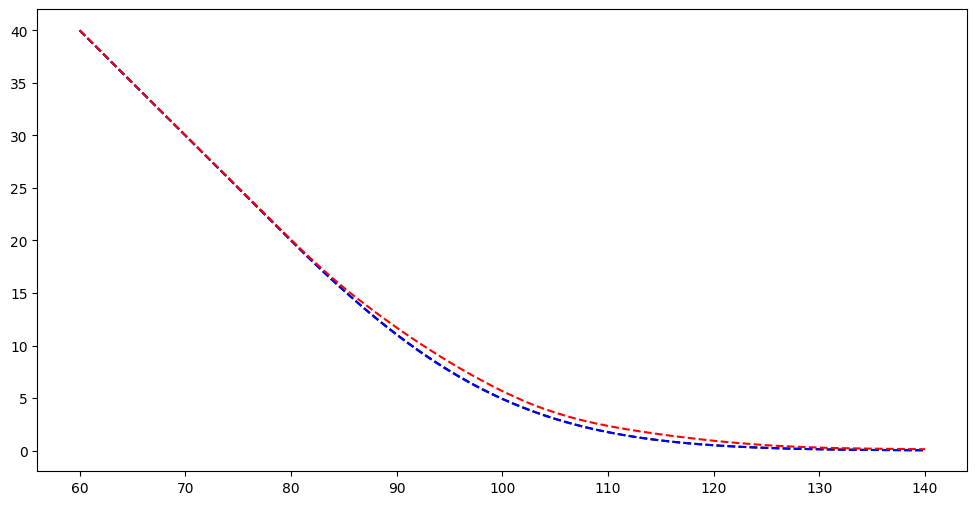

In [4]:
# Plotting the results 
plt.figure(figsize=(12, 6))
plt.plot(np.arange(60,141), real_prices, label='Real Price', color='black', linestyle='--')
plt.plot(np.arange(60,141), lower_bound, label='LS Lower Bound', color='blue', linestyle='--')
plt.plot(np.arange(60,141), upper_bound_rhg, label='RHG Upper Bound', color='red', linestyle='--')
